# Q1 — Which brands cost more (or less) per GB / TB, and is the ranking stable?

**Question.** For the unit that buyers actually compare — **USD per GB for DDR5** and **USD per TB for NVMe** — which brands carry a *premium* or a *discount* relative to the market, and how **stable is the brand ranking** (over time, across ZIP markets, across capacity tiers, and when the sample of products changes)?

**Why it matters.** A buyer comparing "Brand A vs Brand B" usually looks at price per capacity. But brands also differ in *what* they sell (faster kits, bigger drives, PCIe 5.0…). A raw comparison mixes **brand effect** with **product-mix effect** — the two should not be confused. So we report a raw premium *and* a like-for-like premium, each with an honest uncertainty interval, and we test whether the ranking would survive a different sample. **Who cares / what it informs:** a buyer deciding whether a brand's higher price per GB / TB is a real brand premium or just a different kind of product, and whether a cheaper brand is a like-for-like bargain.

**Plan**
1. Load, add flags (`src/cleaning.py`), apply explicit, logged filters (unresolved capacity **must** go here: without capacity there is no price per GB / TB).
2. Build the unit of analysis: **one row per product** (title), because the same title has (almost always) the same price in every ZIP (checked below).
3. Brand extraction (`src/parse_titles.py`) + a brand-cleaning layer + **brand audit** (to be checked by eye).
4. Raw premium vs **adjusted premium** (log-linear model with capacity tier, form factor, speed / PCIe generation as controls) with **product-level bootstrap CIs**.
5. **Rank stability**: bootstrap rank intervals, split-half reliability, first vs last window, ZIP markets, capacity tiers.
6. Robustness (D6): 9 alternative analysis choices.
7. Answer, practical meaning, limitations.

> **Filters.** This question needs price **per GB / TB**, so rows with unresolved capacity are dropped (4,357 in the raw data, 4,340 of them after the noise rows are removed; logged below). The 17 complete-computer rows and 11 NAS-appliance rows (`is_noise`) are dropped as well.

In [1]:
import os
import re
import sys
import itertools
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.enable_last_resort"] = False
from scipy import stats

sys.path.insert(0, str(ROOT))          # repo root (NOT src/, see io.py docstring)
from src.io import load_raw
from src.cleaning import (add_flags, analysis_view, check_noise_flags, check_normalized_price,
                          flag_outliers_iqr, RowLog)
from src.parse_titles import add_parsed_features

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

CATS = ["DDR5", "NVMe"]
UNIT = {"DDR5": "USD per GB", "NVMe": "USD per TB"}
SERIES_ID = {"DDR5": "ddr5_memory", "NVMe": "nvme_ssd"}
PKEY = ["category", "product_name", "quantity_value"]   # product = same title (+ same capacity) in one category
MIN_PRODUCTS = {"DDR5": 5, "NVMe": 10}   # a brand is "ranked" only if it has this many distinct products in the category
MIN_ALT = {"DDR5": (3, 10), "NVMe": (5, 15)}   # lower / higher threshold for the robustness section
B_BOOT = 1000         # bootstrap replicates
SEED = 42

## 1. Load and filter (every step logs its row count)

In [2]:
raw = load_raw(columns="keep", validate=True)
flagged = add_flags(raw)
log = RowLog()
log.note(flagged, "load raw + add flags", reason="no rows change")
display(check_noise_flags(flagged))      # full data: 17 system rows / 5 titles, 11 NAS rows / 2 titles

# Q1 needs price PER GB / TB -> drop unresolved capacity AND complete systems / NAS appliances.
df = analysis_view(flagged, log=log, drop_unresolved=True, drop_noise=True)

# Used only by the robustness section ("keep noise rows"): unresolved dropped, noise rows kept.
df_noise = flagged[~flagged["is_unresolved"]]

print("recorded normalized_price_amount vs price_amount / capacity (data card: agree within USD 0.011):")
print(pd.Series(check_normalized_price(df)).to_string())
log.table()

[OK] All 12 checks match the Kaggle data card.
[load raw + add flags] 127,843 -> 127,843 rows (removed 0)


,check,expected (full data),actual,ok
0,system-noise rows (data card: 17),17,17,True
1,system-noise titles (data card: 5),5,5,True
2,NAS rows,11,11,True
3,NAS titles,2,2,True
4,DDR5 rows unresolved but NOT flagged,0,0,True


[drop complete-system / NAS rows (DDR5 category noise)] 127,843 -> 127,815 rows (removed 28)
[drop unresolved capacity] 127,815 -> 123,475 rows (removed 4,340)
recorded normalized_price_amount vs price_amount / capacity (data card: agree within USD 0.011):
n_compared                   1.234750e+05
max_abs_diff                 5.000032e-09
n_over_tol                   0.000000e+00
n_blank_norm_but_resolved    0.000000e+00
n_norm_but_unresolved        0.000000e+00


,step,rows_before,rows_after,rows_removed,reason
0,load raw + add flags,127843,127843,0,no rows change
1,drop complete-system / NAS rows (DDR5 category...,127843,127815,28,laptop/desktop/mini-PC and NAS listings are no...
2,drop unresolved capacity,127815,123475,4340,"quantity unknown -> normalised price blank, ca..."


**Which per-unit price?** We use `price_per_unit_recomputed` = `price_amount / capacity` (GB for DDR5, TB for NVMe, 1,000 GB = 1 TB; see `cleaning.add_flags`). It is reproducible from the two raw columns and the check above confirms it agrees with the source's `normalized_price_amount`. DDR5 capacity is the **total kit capacity** (a 2×16 GB kit = 32 GB), so DDR5 USD/GB is per GB of the whole kit.

## 2. Unit of analysis: one row per product

**Why not analyse rows directly.** The same title is priced (almost always) identically in the 12 ZIP markets, so rows from different ZIPs are mostly *copies*, not independent observations. A row-level brand comparison would count one product up to 12 ZIPs × 29 days times and make every interval far too narrow. So the unit here is the **product** = `category × product_name × quantity_value`, and its per-unit price is the **median** over all its listing rows. First we check the claim on this data.

In [3]:
# (1) Is the price of a title really the same in all ZIPs on a given day?
pd_day = df.groupby(["category", "product_name", "observed_date"], observed=True)["price_amount"].agg(["nunique", "size"])
multi = pd_day[pd_day["size"] > 1]
print(f"product-days listed in >1 row: {len(multi):,}; share where the rows disagree on price: {(multi['nunique'] > 1).mean():.2%}")

# (2) Does a title ever carry more than one capacity?
cap_per_title = df.groupby(["category", "product_name"], observed=True)["quantity_value"].nunique()
print(f"titles with more than one quantity_value: {(cap_per_title > 1).sum()} of {len(cap_per_title):,}")

# (3) When ZIPs disagree, by how much?
gd = df.groupby(["category", "product_name", "observed_date"], observed=True)["price_amount"].agg(["min", "max"])
dis = gd[gd["max"] > gd["min"]]
print(f"\nproduct-days with different prices across rows: {len(dis):,} of {len(gd):,}")
print("max/min price ratio on those product-days:")
print((dis["max"] / dis["min"]).describe(percentiles=[.5, .9, .99]).round(3).to_string())
print(dis.reset_index().groupby("category", observed=True).size().rename("disagreeing product-days").to_string())

product-days listed in >1 row: 13,894; share where the rows disagree on price: 8.13%
titles with more than one quantity_value: 0 of 1,128

product-days with different prices across rows: 1,129 of 15,578
max/min price ratio on those product-days:
count    1129.000
mean        1.028
std         0.033
min         1.000
50%         1.019
90%         1.068
99%         1.163
max         1.245
category
DDR5    179
NVMe    950


In [4]:
def build_products(d):
    """One row per product. ppu = median price per unit over all of the product's rows."""
    d = d.assign(quantity_unit=d["quantity_unit"].astype(str))
    g = d.groupby(PKEY, observed=True)
    prod = g.agg(quantity_unit=("quantity_unit", "first"),
                 n_rows=("price_amount", "size"), n_days=("observed_date", "nunique"),
                 n_zips=("geography_id", "nunique"),
                 price=("price_amount", "median"),
                 ppu=("price_per_unit_recomputed", "median"),
                 ppu_min=("price_per_unit_recomputed", "min"),
                 ppu_max=("price_per_unit_recomputed", "max")).reset_index()
    prod["category"] = prod["category"].astype(str)
    prod["series_id"] = prod["category"].map(SERIES_ID)
    return prod

prod = log.step(df, "collapse to product (median price per unit)", build_products,
                reason="same title = same price in every ZIP; product is the independent unit")
print(prod.groupby("category").agg(products=("ppu", "size"), listing_rows=("n_rows", "sum"),
                                   median_days=("n_days", "median"), median_zips=("n_zips", "median")))
print(f"share of products whose price per unit changed during the 29 days: {(prod['ppu_max'] > prod['ppu_min']).mean():.1%}")

[collapse to product (median price per unit)] 123,475 -> 1,128 rows (removed 122,347)
          products  listing_rows  median_days  median_zips
category                                                  
DDR5           221         18622          8.0         12.0
NVMe           907        104853         13.0         12.0
share of products whose price per unit changed during the 29 days: 46.3%


**Decision (a).** The unit is the product. The check above shows that most product-days have one price across ZIPs, but a minority do not: 1,129 of the 13,894 product-days with more than one row (8.1 %) show different prices across ZIPs. The gaps are small — median max/min ratio 1.019, 90 % of them ≤ 1.068, 99 % ≤ 1.163, largest 1.245 (950 of the 1,129 are NVMe). The product median absorbs them, and section 5.4 checks whether ZIP-specific prices change the brand ranking. A product's price can still drift over the 29 days (46 % of products changed price per unit, see above), so its median mixes early and late prices; section 5.3 repeats the analysis inside the first and last 7-day windows to make sure this does not drive the result.

## 3. Brand extraction, controls and the brand audit

`parse_titles.add_parsed_features` gives `brand` (first token of the title, with a few aliases), `speed_mhz`, `form_factor`, `kit_modules`, `pcie_gen`. A first-token rule fails for multi-word brands (`SK hynix` → `SK`, `Silicon Power` → `SILICON`) and for titles that start with a capacity or a product word. So we add a small, **visible** cleaning layer (`BRAND_FIX`, `_JUNK`) on top and print an audit that **must be checked by eye** after the first run.

**Controls** (like-for-like comparison, D4): capacity tier, form factor, and — DDR5: speed bucket and kit type; NVMe: PCIe generation. Unparsed values become an explicit `unk` level instead of being dropped.

> **Note on NAS titles.** `parse_titles._NAS_PATTERN` now uses the same rule as `cleaning.py` (a complete NAS box needs "bay", "diskless" or "network attached storage"), so RAM sold "for Synology NAS" is parsed as normal memory. Complete appliances are removed by `cleaning.is_noise`.

In [5]:
# Multi-word brands / aliases that the first-token rule cannot see. Starter list: extend after reading the audit.
BRAND_FIX = {"SK": "SK HYNIX", "SILICON": "SILICON POWER", "T-FORCE": "TEAMGROUP", "T-CREATE": "TEAMGROUP",
             "XPG": "ADATA", "FURY": "KINGSTON", "AORUS": "GIGABYTE", "WD_BLACK": "WESTERN DIGITAL",
             "WD": "WESTERN DIGITAL", "WESTERN": "WESTERN DIGITAL", "TEAM": "TEAMGROUP",
             "G": "G.SKILL", "GSKILL": "G.SKILL", "SKHYNIX": "SK HYNIX", "HYNIX": "SK HYNIX",
             "NEWSAMSUNG": "SAMSUNG", "PREDATOR": "ACER"}
# Titles that start with a capacity / product word instead of a brand.
_JUNK = re.compile(r"^(?:\d|(?:DDR\d?|NVME|M\.2|PCIE|SSD|RAM|MEMORY|INTERNAL|LAPTOP|DESKTOP|GAMING|GENERIC|NEW|OEM\w*|UNKNOWN)\b)")
# Part numbers that identify the maker (Samsung OEM drives are sold under their model number).
_MODEL_BRAND = [(re.compile(r"^(?:PM9\w*|MZ-\w+|MZV\w+)"), "SAMSUNG")]
NON_BRANDS = ("UNBRANDED", "OTHER")

def clean_brand(b):
    b = re.sub(r"[™®©]", "", str(b)).strip().upper()
    b = BRAND_FIX.get(b, b)
    for pat, name in _MODEL_BRAND:
        if pat.match(b):
            b = name
    return "UNBRANDED" if (not b or _JUNK.match(b)) else b

def add_controls(p):
    p = p.copy()
    cap_gb = np.where(p["quantity_unit"] == "gigabytes", p["quantity_value"],
              np.where(p["quantity_unit"] == "terabytes", p["quantity_value"] * 1000.0, np.nan))
    p["cap_gb"] = cap_gb
    is5 = (p["category"] == "DDR5").to_numpy()
    t5 = pd.cut(cap_gb, [0, 8, 16, 32, 64, np.inf], labels=["<=8GB", "16GB", "24-32GB", "48-64GB", ">=96GB"]).astype(str)
    tn = pd.cut(cap_gb, [0, 300, 600, 1200, 2400, np.inf], labels=["<=256GB", "512GB", "1TB", "2TB", ">=4TB"]).astype(str)
    p["cap_tier"] = np.where(is5, t5, tn)
    p["speed"] = pd.cut(p["speed_mhz"], [0, 5200, 5600, 6000, 6400, np.inf], right=False,
                        labels=["<5200", "5200-5599", "5600-5999", "6000-6399", ">=6400"]).astype(str).replace("nan", "unk")
    km = p["kit_modules"].astype(float)
    p["kit"] = np.select([km == 1, km == 2, km >= 3], ["single", "2-kit", "3+"], default="unk")
    ddr_form = np.where(p["form_factor"].isin(["UDIMM", "SODIMM"]), p["form_factor"], "other")
    p["form"] = np.where(is5, ddr_form, p["form_factor"])
    p["pcie"] = np.where(p["pcie_gen"].notna(), "Gen" + p["pcie_gen"].fillna(0).astype(int).astype(str), "unk")
    return p

def enrich(prod_in):
    n = len(prod_in)
    p = add_parsed_features(prod_in)                 # runs the regexes on unique (title, series, quantity) only
    assert len(p) == n, "title parsing must not change the number of products"
    p["brand_raw"] = p["brand"]
    p["brand"] = p["brand_raw"].map(clean_brand)
    return add_controls(p)

CONTROLS = {"DDR5": ["cap_tier", "form", "speed", "kit"], "NVMe": ["cap_tier", "pcie", "form"]}

prod_en = enrich(prod)
log.note(prod_en, "parse titles: brand + controls", reason="adds columns only")
for c in CATS:
    print(f"--- {c}: share of products per control level ---")
    for col in CONTROLS[c]:
        print(col, prod_en.loc[prod_en["category"] == c, col].value_counts(normalize=True).round(3).to_dict())

[parse titles: brand + controls] 1,128 -> 1,128 rows (removed 0)
--- DDR5: share of products per control level ---
cap_tier {'24-32GB': 0.412, '48-64GB': 0.213, '16GB': 0.19, '>=96GB': 0.145, '<=8GB': 0.041}
form {'UDIMM': 0.869, 'SODIMM': 0.131}
speed {'6000-6399': 0.538, '5600-5999': 0.24, '>=6400': 0.118, '<5200': 0.072, '5200-5599': 0.032}
kit {'2-kit': 0.774, 'single': 0.181, '3+': 0.045}
--- NVMe: share of products per control level ---
cap_tier {'1TB': 0.294, '512GB': 0.221, '2TB': 0.216, '<=256GB': 0.184, '>=4TB': 0.085}
pcie {'Gen4': 0.505, 'Gen3': 0.312, 'unk': 0.115, 'Gen5': 0.068}
form {'M.2_2280': 0.555, 'M.2_Unspecified': 0.155, 'M.2_2230': 0.142, 'Other_SSD': 0.075, 'M.2_2242': 0.073}


In [6]:
# ---- BRAND AUDIT: read this after the first run and extend BRAND_FIX / _JUNK if something is wrong ----
audit = (prod_en.groupby(["category", "brand"])
         .agg(n_products=("ppu", "size"), n_rows=("n_rows", "sum"), median_ppu=("ppu", "median"))
         .reset_index().sort_values(["category", "n_products"], ascending=[True, False]))
for c in CATS:
    a = audit[audit["category"] == c]
    print(f"=== {c}: {len(a)} distinct brands; {(a['n_products'] >= MIN_PRODUCTS[c]).sum()} with >= {MIN_PRODUCTS[c]} products ===")
    display(a.head(30).round(2).reset_index(drop=True))
    small = prod_en[(prod_en["category"] == c) &
                    prod_en["brand"].isin(a.loc[a["n_products"] < MIN_PRODUCTS[c], "brand"])]
    print(f"titles of brands below the threshold (first 15 by listing rows) - look for brand-parsing errors:")
    print(small.sort_values("n_rows", ascending=False)[["brand_raw", "brand", "product_name"]]
          .head(15).to_string(index=False, max_colwidth=70))

=== DDR5: 22 distinct brands; 10 with >= 5 products ===


,category,brand,n_products,n_rows,median_ppu
0,DDR5,G.SKILL,71,5945,18.28
1,DDR5,CORSAIR,27,3719,14.69
2,DDR5,CRUCIAL,23,1761,14.14
3,DDR5,TEAMGROUP,16,1917,15.00
4,DDR5,A-TECH,15,621,15.53
5,DDR5,KINGSTON,15,721,18.12
6,DDR5,PATRIOT,15,1261,13.62
7,DDR5,ACER,8,342,14.89
8,DDR5,GIGASTONE,5,99,13.89
9,DDR5,PNY,5,760,13.59


titles of brands below the threshold (first 15 by listing rows) - look for brand-parsing errors:
 brand_raw      brand                                                           product_name
     LEXAR      LEXAR Lexar OC DDR5 RAM 1x8GB 6000MHz CL38 288-Pin UDIMM Desktop Memory |...
     BIWIN      BIWIN Biwin Black Opal DW100 DDR5 RGB RAM 48GB (24GBx2) 6000MHz CL28 Comp...
     LEXAR      LEXAR Lexar Thor Z RGB DDR5 RAM 32GB Kit (2x16GB) 6000MHz CL38 DRAM 288-P...
     LEXAR      LEXAR Lexar ARES Gen2 RGB DDR5 RAM 32GB Kit (2x16GB) 6000MHz CL30, 288-Pi...
   SAMSUNG    SAMSUNG Samsung 8GB DDR5 5600MHz PC5-44800 CL46 SODIMM 1Rx16 Single Rank 1....
     LEXAR      LEXAR Lexar Thor Z Series RGB DDR5 RAM 32GB Kit (2x16GB) 6000 MHz, DRAM 2...
   SAMSUNG    SAMSUNG Samsung 16GB DDR5 5600MHz PC5-44800 CL46 SODIMM 1Rx8 Single Rank 1....
  ANACOMDA   ANACOMDA ANACOMDA DDR5 6000MHz CL38 Gaming RAM 16GB Black, Intel XMP 3.0 Rea...
     NEMIX      NEMIX NEMIX RAM 32GB DDR5 5600MHz (1x32GB) SODIMM 

,category,brand,n_products,n_rows,median_ppu
0,NVMe,UNBRANDED,118,10214,214.24
1,NVMe,WESTERN DIGITAL,67,11099,200.00
2,NVMe,SAMSUNG,53,8591,253.89
3,NVMe,CRUCIAL,40,4666,182.30
4,NVMe,FIKWOT,37,5029,167.95
5,NVMe,FANXIANG,33,4498,179.98
6,NVMe,KINGSPEC,31,4148,165.97
7,NVMe,INLAND,28,1913,192.49
8,NVMe,BESTOSS,27,3112,160.49
9,NVMe,SANDISK,23,2339,235.98


titles of brands below the threshold (first 15 by listing rows) - look for brand-parsing errors:
brand_raw         brand                                                           product_name
  ADDLINK       ADDLINK Addlink New S91 2TB 2230 NVMe High Performance PCIe Gen4x4 2230 3D ...
    RAOYI         RAOYI RAOYI 1TB NVMe Internal Solid State Drive M.2 2280 PCIe Gen4x4 SSD,...
    INTEL         INTEL                    Intel 256GB PCIe-NVMe SSD, 2280 M.2, SSDPEKKF256G8L
    BIWIN         BIWIN BIWIN M350 NVMe Gen4 SSD 2TB, PCIe 4.0, M.2 2280, Read Speeds Up to...
     ACER          ACER Acer MA200 M.2 2230 SSD NVMe 1TB, PCIe Gen 4, Read Speeds Up to 520...
      MSI           MSI msi Gaming SPATIUM M480 PRO PCIe 4.0 NVMe M.2 1TB Internal SSD (PCI...
    INTEL         INTEL Intel 660p Series M.2 2280 1TB PCIe NVMe 3.0 x4 3D2, QLC Internal S...
    NETAC         NETAC Netac 1TB PCIe Gen4x4 M.2 SSD Up to 7,300 MB/s NVMe Internal SSD wi...
  SILICON SILICON POWER   Silicon Power 1TB - NV

**Decision (b).** Only brands with enough distinct products are ranked: **≥ 5 for DDR5** (221 products) and **≥ 10 for NVMe** (907 products, many small brands). With a threshold of 5, NVMe had 48 ranked brands whose CIs reached ±50 pp and whose rank intervals spanned 30+ places; a premium based on 5–6 products is mostly one product's price. All other brands and `UNBRANDED` are pooled into `OTHER`: they stay in the model (so they do not distort the controls) but are not ranked. A lower and a higher threshold are in the robustness section.

> **Audit reading (after the brand-cleaning pass).**
> - **DDR5:** 22 distinct brands, 10 ranked; ranked brands cover 90 % of products and 92 % of listing rows. Lexar (4 products), Samsung (2), Acclamator (3) and the rest fall below the threshold and sit in `OTHER`.
> - **NVMe:** 94 distinct brands, 27 ranked, but ranked brands cover only **66 % of products / 72 % of listing rows**: 118 products are `UNBRANDED` (title starts with a capacity or product word) and about 190 more are small brands below the threshold. The NVMe ranking therefore says nothing about roughly a third of the catalogue.
> - Transcend (9 products) and Biwin (8) just miss the NVMe threshold of 10. Short tokens such as `SIX`, `IST`, `CUK` look like seller or sub-brand labels; they stay below the threshold and do not enter the ranking.
> - Samsung-OEM part numbers (`PM9…`, `MZ-…`), `SKHYNIX`/`HYNIX` and `NewSamsung` are now merged into their brand (they moved Samsung from 47 to 53 and SK hynix from 11 to 15 products).

## 4. Method: raw and adjusted brand premium (D3, D4, D5)

**Derived variable (D3).** `y = ln(price per unit)` of each product. Log makes a +10 % / −10 % difference symmetric and tames the right skew of USD/GB and USD/TB.

**Model.** For each category (equal weight per product):

`y = brand effect + capacity tier + form factor + (speed bucket, kit type | PCIe generation) + error`

- **Brand premium** of brand *b* = `exp(β_b − β̄) − 1`, where β̄ is the **product-weighted average brand effect**. Read: "this brand is X % above / below the average product in the market, **at the same capacity tier, form factor and speed / PCIe generation**." The reference is the market, not the cheapest brand.
- **Raw premium** = the same formula **without controls**, so raw → adjusted isolates what the controls change. If raw and adjusted differ a lot, part of the "brand premium" is just what the brand sells.
- **How much does brand explain?** R² of controls only, brand only, and both.

**Uncertainty (D5).** Percentile **bootstrap that resamples products** (1,000 replicates). The product is the right cluster because ZIP copies were collapsed in section 2. Limits: two products of one product line (e.g. two Crucial Pro kits) are still treated as independent, so intervals are somewhat optimistic. We report the CI and whether it excludes 0, **not p-values**.

In [7]:
def prep(p, cat, min_products=None, ctrl_cols=None, weight_col=None, ppu_col="ppu", ranked=None):
    """Design objects for one category. brand dummies carry the (implicit) intercept."""
    p = p[p["category"] == cat].reset_index(drop=True)
    if ranked is None:
        min_products = MIN_PRODUCTS[cat] if min_products is None else min_products
        cnt = p["brand"].value_counts()
        ranked = [b for b, n in cnt.items() if n >= min_products and b not in NON_BRANDS]
    grp = p["brand"].where(p["brand"].isin(ranked), "OTHER")
    Bdf = pd.get_dummies(grp, dtype=float)
    cols = CONTROLS[cat] if ctrl_cols is None else ctrl_cols
    C = (pd.get_dummies(p[cols].astype(str), drop_first=True, dtype=float).to_numpy()
         if cols else np.zeros((len(p), 0)))
    w = p[weight_col].to_numpy(float) if weight_col else np.ones(len(p))
    return {"cat": cat, "p": p, "grp": grp, "ranked": list(ranked), "brands": list(Bdf.columns),
            "B": Bdf.to_numpy(), "C": C, "y": np.log(p[ppu_col].to_numpy(float)), "w": w}

def _wls(X, y, w):
    sw = np.sqrt(w)
    return np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]

def premium(y, B, C, w):
    """exp(beta_b - weighted mean beta) - 1 for every brand column; NaN where the brand is absent."""
    beta = _wls(np.hstack([B, C]), y, w)
    b = beta[:B.shape[1]]
    mass = (B * w[:, None]).sum(0)
    ref = (mass / mass.sum() * b).sum()
    return np.where(mass > 0, np.expm1(b - ref), np.nan)

def fit(o):
    return pd.Series(premium(o["y"], o["B"], o["C"], o["w"]), index=o["brands"])

def boot(o, n_boot=B_BOOT, seed=SEED):
    """Bootstrap over PRODUCTS (rows of the product table)."""
    rng = np.random.default_rng(seed)
    n = len(o["y"])
    out = np.empty((n_boot, len(o["brands"])))
    for i in range(n_boot):
        k = rng.integers(0, n, n)
        out[i] = premium(o["y"][k], o["B"][k], o["C"][k], o["w"][k])
    return pd.DataFrame(out, columns=o["brands"])

def r2_table(o):
    y, w, n = o["y"], o["w"], len(o["y"])
    def r2(X):
        res = y - X @ _wls(X, y, w)
        r = 1 - (w * res ** 2).sum() / (w * (y - np.average(y, weights=w)) ** 2).sum()
        k = np.linalg.matrix_rank(X)
        return r, 1 - (1 - r) * (n - 1) / (n - k), k
    ones = np.ones((n, 1))
    rows = {"controls only": np.hstack([ones, o["C"]]), "brand only": o["B"], "brand + controls": np.hstack([o["B"], o["C"]])}
    return pd.DataFrame({k: r2(X) for k, X in rows.items()}, index=["R2", "adj_R2", "n_params"]).T

def brand_table(o, o_raw, boots):
    g = (o["p"].assign(grp=o["grp"]).groupby("grp")
         .agg(n_products=("ppu", "size"), n_rows=("n_rows", "sum"), median_ppu=("ppu", "median")))
    mkt_med = o["p"]["ppu"].median()
    t = g.copy()
    t["median_ratio_%"] = (t["median_ppu"] / mkt_med - 1) * 100
    t["prem_raw_%"] = fit(o_raw) * 100
    t["prem_adj_%"] = fit(o) * 100
    t["ci_low_%"] = boots.quantile(.025) * 100
    t["ci_high_%"] = boots.quantile(.975) * 100
    t["share_boot_>0"] = (boots > 0).sum() / boots.notna().sum()
    t["ci_excludes_0"] = (t["ci_low_%"] > 0) | (t["ci_high_%"] < 0)
    return t.sort_values("prem_adj_%", ascending=False)

OBJ, RAW_OBJ, BOOT, TAB = {}, {}, {}, {}
for c in CATS:
    OBJ[c] = prep(prod_en, c)
    RAW_OBJ[c] = prep(prod_en, c, ctrl_cols=[], ranked=OBJ[c]["ranked"])
    BOOT[c] = boot(OBJ[c])
    TAB[c] = brand_table(OBJ[c], RAW_OBJ[c], BOOT[c])
    o = OBJ[c]
    print(f"=== {c} ({UNIT[c]}): {len(o['p']):,} products, {len(o['ranked'])} ranked brands, "
          f"ranked brands cover {(o['grp'] != 'OTHER').mean():.0%} of products / "
          f"{o['p'].loc[(o['grp'] != 'OTHER').to_numpy(), 'n_rows'].sum() / o['p']['n_rows'].sum():.0%} of listing rows ===")
    display(r2_table(o).round(3))
    display(TAB[c].round(2))

=== DDR5 (USD per GB): 221 products, 10 ranked brands, ranked brands cover 90% of products / 92% of listing rows ===


,R2,adj_R2,n_params
controls only,0.376,0.343,12.0
brand only,0.345,0.313,11.0
brand + controls,0.559,0.512,22.0


,n_products,n_rows,median_ppu,median_ratio_%,prem_raw_%,prem_adj_%,ci_low_%,ci_high_%,share_boot_>0,ci_excludes_0
grp,,,,,,,,,,
KINGSTON,15,721,18.12,18.61,9.75,13.73,6.16,21.74,1.00,True
G.SKILL,71,5945,18.28,19.62,17.86,13.15,8.72,19.17,1.00,True
A-TECH,15,621,15.53,1.63,-2.94,-2.22,-13.50,8.29,0.32,False
CORSAIR,27,3719,14.69,-3.89,-7.11,-4.88,-9.17,-0.29,0.02,True
CRUCIAL,23,1761,14.14,-7.44,-12.14,-5.82,-10.61,-1.21,0.01,True
OTHER,21,1476,13.44,-12.07,-9.16,-6.72,-14.82,0.31,0.03,False
ACER,8,342,14.89,-2.56,-7.26,-6.80,-13.77,0.21,0.04,False
TEAMGROUP,16,1917,15.00,-1.84,-7.15,-8.36,-12.68,-4.10,0.00,True
PNY,5,760,13.59,-11.04,-16.61,-11.87,-18.31,-4.47,0.00,True


=== NVMe (USD per TB): 907 products, 27 ranked brands, ranked brands cover 66% of products / 72% of listing rows ===


,R2,adj_R2,n_params
controls only,0.424,0.417,12.0
brand only,0.202,0.178,28.0
brand + controls,0.543,0.523,39.0


,n_products,n_rows,median_ppu,median_ratio_%,prem_raw_%,prem_adj_%,ci_low_%,ci_high_%,share_boot_>0,ci_excludes_0
grp,,,,,,,,,,
MICRON,11,1102,284.96,45.43,67.71,41.17,1.30,105.60,0.98,True
DELL,17,2707,329.00,67.91,43.99,32.41,19.78,47.60,1.00,True
SAMSUNG,53,8591,253.89,29.57,33.30,29.87,21.00,39.92,1.00,True
CORSAIR,11,1657,200.00,2.07,7.19,29.74,9.37,54.74,1.00,True
SANDISK,23,2339,235.98,20.43,12.92,21.80,11.30,33.77,1.00,True
WESTERN DIGITAL,67,11099,200.00,2.07,5.68,16.74,8.82,25.21,1.00,True
SK HYNIX,15,2539,298.59,52.39,43.60,14.57,-4.61,37.77,0.94,False
KINGSTON,20,2025,226.95,15.83,5.55,10.65,-0.73,22.28,0.97,False
GAMERKING,19,1528,276.45,41.09,24.61,8.18,-0.39,17.86,0.97,False


**Reading the tables (numbers from the run above).**

*How much does brand explain?* In log USD per unit, brand alone gives R² = 0.345 (DDR5) and 0.202 (NVMe); the controls alone give 0.376 and 0.424; both together give 0.559 and 0.543 (adjusted 0.512 and 0.523). Brand adds about 0.18 (DDR5) and 0.12 (NVMe) of R² on top of capacity, form factor and speed / PCIe, so a brand matters, but **what a product is (capacity tier, PCIe generation, speed) explains as much or more of its price per GB / TB than who made it.** In NVMe the controls explain about twice as much as brand alone.

*Which premiums are distinguishable from zero (95 % CI over products)?*
- **DDR5 (8 of 10 brands).** Premiums: **Kingston +13.7 %** [+6.2, +21.7] and **G.SKILL +13.1 %** [+8.7, +19.2]. Discounts: Corsair −4.9 % [−9.2, −0.3], Crucial −5.8 % [−10.6, −1.2], TeamGroup −8.4 % [−12.7, −4.1], PNY −11.9 % [−18.3, −4.5], **Patriot −16.4 %** [−20.6, −12.0], Gigastone −16.5 % [−32.7, −1.4] (5 products, very wide). A-Tech (−2.2 %) and Acer (−6.8 %, CI reaches +0.3) are not distinguishable from the market. Corsair's interval only just excludes 0.
- **NVMe (15 of 27 brands).** Premiums: **Samsung +29.9 %** [+21.0, +39.9] (53 products, the best-supported premium), Dell +32.4 % [+19.8, +47.6], Corsair +29.7 % [+9.4, +54.7], SanDisk +21.8 % [+11.3, +33.8], Western Digital +16.7 % [+8.8, +25.2], and Micron +41.2 % with a very wide interval [+1.3, +105.6] (11 products). Discounts: SSK, DATO, Bestoss, Fikwot, Fanxiang, Kingspec, Ediloca and Ridata (−6 % to −18 %) and **Patriot −21.4 %** [−26.4, −15.5]. The 12 brands in between, including Crucial, Kingston, Lexar, Sabrent, PNY, Inland, Kioxia, ADATA, TeamGroup and also SK hynix (+14.6 %, CI [−4.6, +37.8]) and Gamerking (+8.2 %), have an interval that contains 0: **their price per TB cannot be told apart from the market average** at this sample size.

*Raw vs adjusted (product-mix effect).* The controls change the picture for several brands:
- NVMe: **Corsair +7.2 % → +29.7 %**, SK hynix +43.6 % → +14.6 %, Micron +67.7 % → +41.2 %, Dell +44.0 % → +32.4 %; TeamGroup −23.6 % → −3.1 %, Lexar −16.7 % → +4.1 %, Sabrent −13.0 % → +0.3 %, Kioxia +13.6 % → −2.7 %. For TeamGroup, Lexar and Sabrent the raw discount is almost entirely product mix (capacity tier, PCIe generation, form factor); for Corsair the like-for-like premium is hidden in the raw numbers.
- DDR5: Crucial −12.1 % → −5.8 % (about half of its raw discount is mix), Kingston +9.7 % → +13.7 %, G.SKILL +17.9 % → +13.1 %, Patriot −14.3 % → −16.4 %.
- Samsung NVMe (+33.3 % raw, +29.9 % adjusted) and Patriot (both categories) hardly change: their gap is a brand-level price difference, not mix.

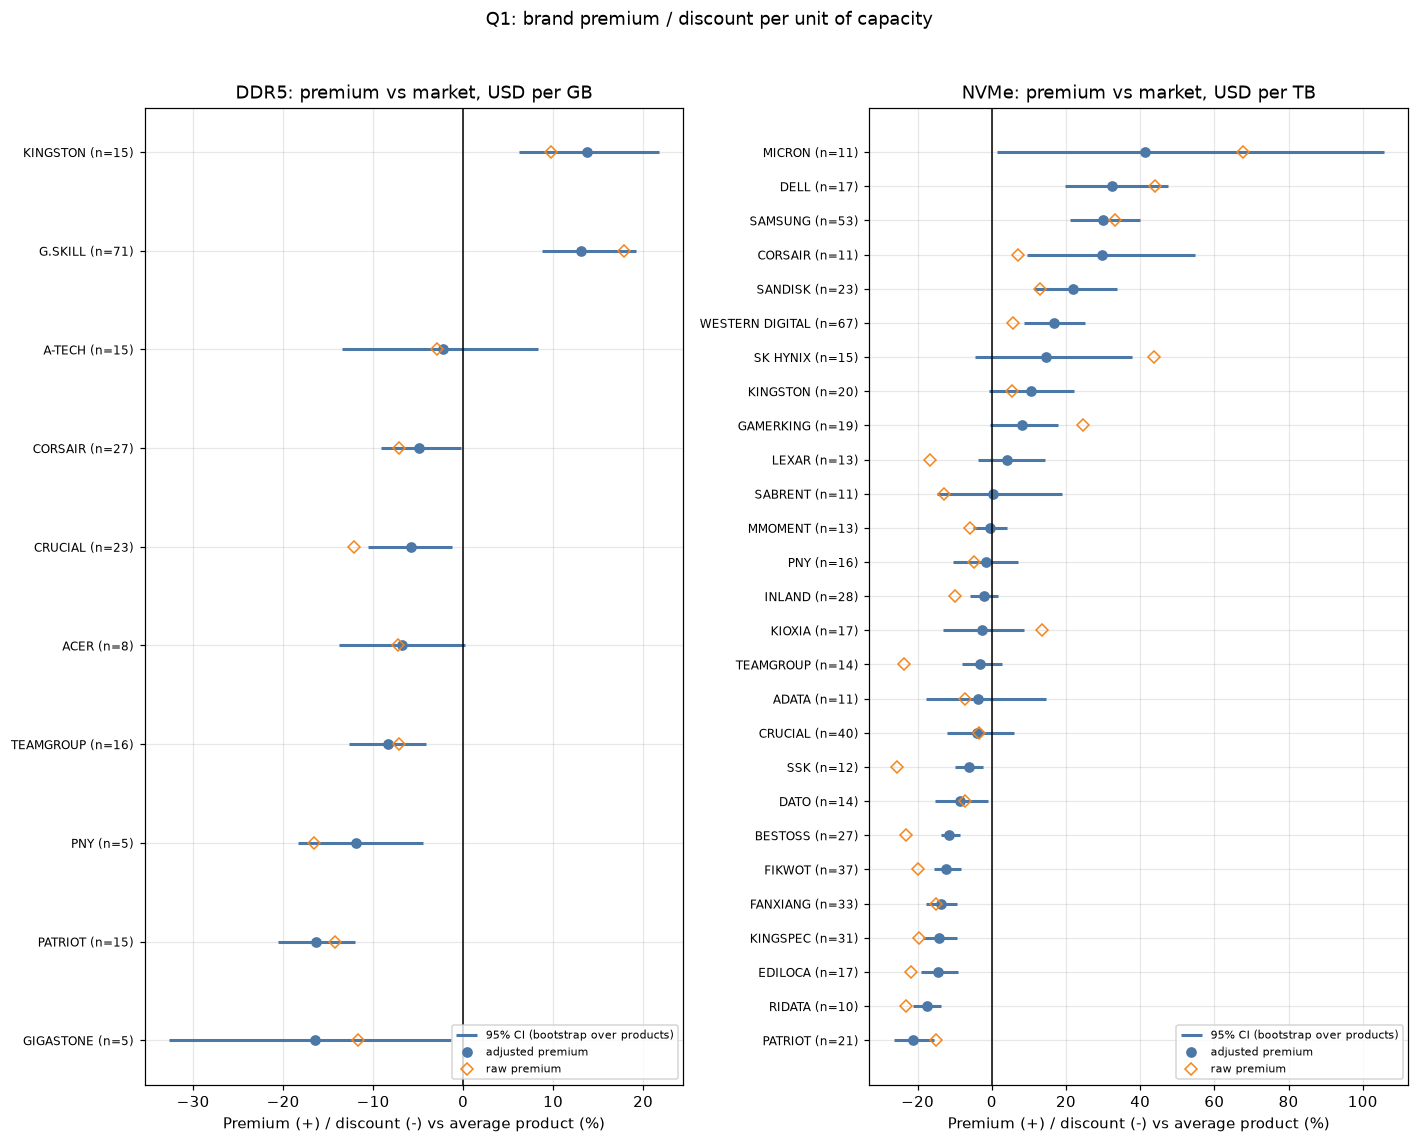

In [8]:
def forest(ax, tab, c):
    t = tab[tab.index != "OTHER"].sort_values("prem_adj_%")
    y = np.arange(len(t))
    ax.hlines(y, t["ci_low_%"], t["ci_high_%"], color="#4C78A8", lw=2, label="95% CI (bootstrap over products)")
    ax.plot(t["prem_adj_%"], y, "o", color="#4C78A8", label="adjusted premium")
    ax.plot(t["prem_raw_%"], y, "D", mfc="none", color="#F58518", label="raw premium")
    ax.axvline(0, color="k", lw=1)
    ax.set_yticks(y); ax.set_yticklabels([f"{b} (n={int(n)})" for b, n in zip(t.index, t["n_products"])], fontsize=8)
    ax.set(title=f"{c}: premium vs market, {UNIT[c]}", xlabel="Premium (+) / discount (-) vs average product (%)")
    ax.legend(fontsize=7, loc="lower right")

fig, ax = plt.subplots(1, 2, figsize=(13, max(4.5, 0.32 * max(len(OBJ[c]["ranked"]) for c in CATS) + 1.5)))
for a, c in zip(ax, CATS):
    forest(a, TAB[c], c)
fig.suptitle("Q1: brand premium / discount per unit of capacity", y=1.02)
plt.tight_layout(); plt.show()

**Reading Plot 1 (numbers from the table above).** Where the orange diamond (raw) sits far from the blue dot (adjusted) the brand's headline premium is driven by what it sells: NVMe Corsair, SK hynix, TeamGroup, Lexar and Sabrent are the clearest cases. Where they coincide (Samsung, Patriot, Fikwot, Bestoss) the premium or discount is a brand effect. Interval widths follow the number of products: Micron (11), Corsair (11), Gigastone (5) are the widest, Samsung (53) and G.SKILL (71) the narrowest.

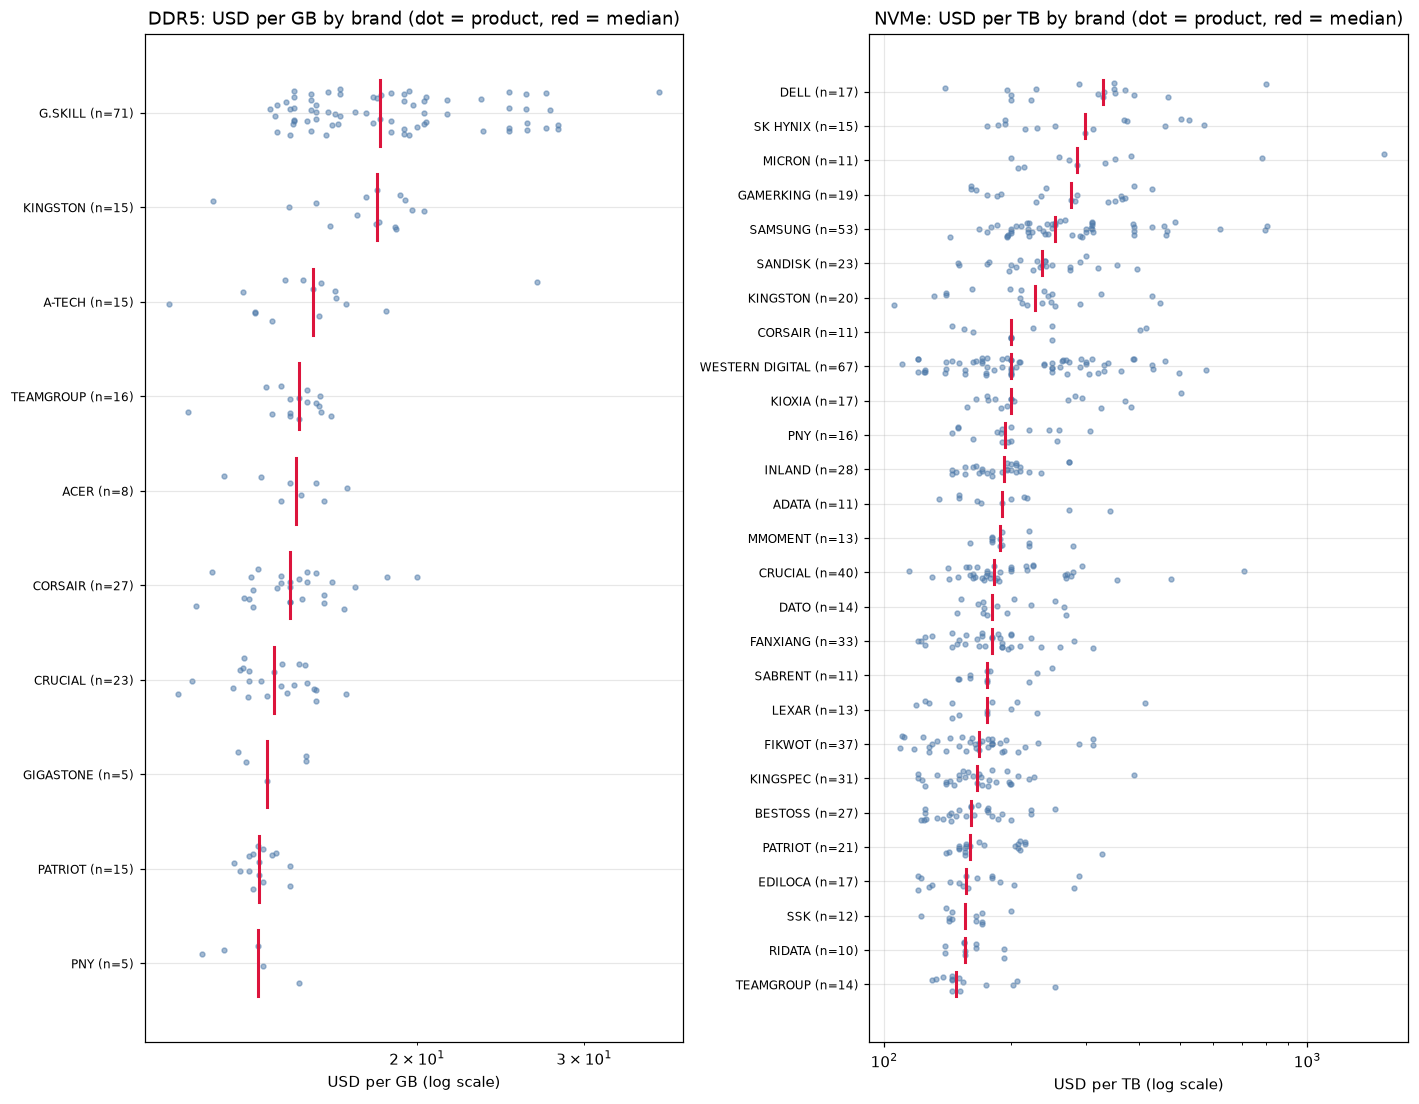

In [9]:
# Plot 2: the raw spread behind the premiums (per product, log scale)
fig, ax = plt.subplots(1, 2, figsize=(13, max(4.5, 0.32 * max(len(OBJ[c]["ranked"]) for c in CATS) + 1.5)))
for a, c in zip(ax, CATS):
    o = OBJ[c]
    order = [b for b in TAB[c].sort_values("median_ppu").index if b in o["ranked"]]
    rng = np.random.default_rng(SEED)
    for i, b in enumerate(order):
        x = o["p"].loc[(o["grp"] == b).to_numpy(), "ppu"].to_numpy()
        a.scatter(x, i + rng.uniform(-.25, .25, len(x)), s=10, alpha=.5, color="#4C78A8")
        a.plot([np.median(x)] * 2, [i - .35, i + .35], color="crimson", lw=2)
    a.set_xscale("log")
    a.set_yticks(range(len(order)))
    a.set_yticklabels([f"{b} (n={int((o['grp'] == b).sum())})" for b in order], fontsize=8)
    a.set(title=f"{c}: {UNIT[c]} by brand (dot = product, red = median)", xlabel=f"{UNIT[c]} (log scale)")
plt.tight_layout(); plt.show()

## 5. Rank stability (does the ranking survive a different sample?)

Rank 1 = **highest** premium. Four angles, from "same data, resampled" to "different data":

- **5.1 Bootstrap rank intervals.** Re-rank brands in each bootstrap replicate: 95 % interval of each brand's rank and the probability of being in the top-3 / bottom-3.
- **5.2 Split-half reliability.** Randomly split *products* in two halves, rank brands in each half, Spearman ρ between halves (500 splits). Half samples are smaller than the full sample, so we also give the Spearman–Brown-corrected value `2ρ/(1+ρ)` as an estimate for the full sample.
- **5.3 First vs last 7 days.** Premium is re-estimated inside each window. **Main version = fixed catalog** (same products in both windows, ≥ 3 days each), so a change in the ranking cannot come from a changing product list. A second version lets the product list differ.
- **5.4 Across ZIP markets** and **5.5 across capacity tiers.**

=== 5.1 DDR5: bootstrap rank intervals (1 = highest premium) ===


,prem_adj_%,rank_point,rank_median,rank_lo,rank_hi,P(top3),P(bottom3)
KINGSTON,13.73,1.0,1.0,1.0,2.00,1.00,0.00
G.SKILL,13.15,2.0,2.0,1.0,2.00,1.00,0.00
A-TECH,-2.22,3.0,3.0,3.0,9.00,0.53,0.08
CORSAIR,-4.88,4.0,4.0,3.0,7.00,0.21,0.01
CRUCIAL,-5.82,5.0,5.0,3.0,8.00,0.06,0.04
ACER,-6.80,6.0,6.0,3.0,8.02,0.12,0.14
TEAMGROUP,-8.36,7.0,7.0,4.0,9.00,0.02,0.21
PNY,-11.87,8.0,8.0,4.0,10.00,0.01,0.72
PATRIOT,-16.36,9.0,9.0,8.0,10.00,0.00,1.00
GIGASTONE,-16.47,10.0,9.0,3.0,10.00,0.04,0.81


=== 5.1 NVMe: bootstrap rank intervals (1 = highest premium) ===


,prem_adj_%,rank_point,rank_median,rank_lo,rank_hi,P(top3),P(bottom3)
MICRON,41.17,1.0,1.0,1.0,11.02,0.70,0.00
DELL,32.41,2.0,2.0,1.0,5.00,0.77,0.00
SAMSUNG,29.87,3.0,3.0,1.0,5.00,0.66,0.00
CORSAIR,29.74,4.0,3.0,1.0,8.00,0.57,0.00
SANDISK,21.80,5.0,5.0,2.0,8.00,0.15,0.00
WESTERN DIGITAL,16.74,6.0,6.0,4.0,9.00,0.02,0.00
SK HYNIX,14.57,7.0,7.0,2.0,16.00,0.11,0.00
KINGSTON,10.65,8.0,8.0,5.0,13.02,0.00,0.00
GAMERKING,8.18,9.0,9.0,6.0,13.00,0.00,0.00
LEXAR,4.11,10.0,10.0,7.0,16.00,0.00,0.00


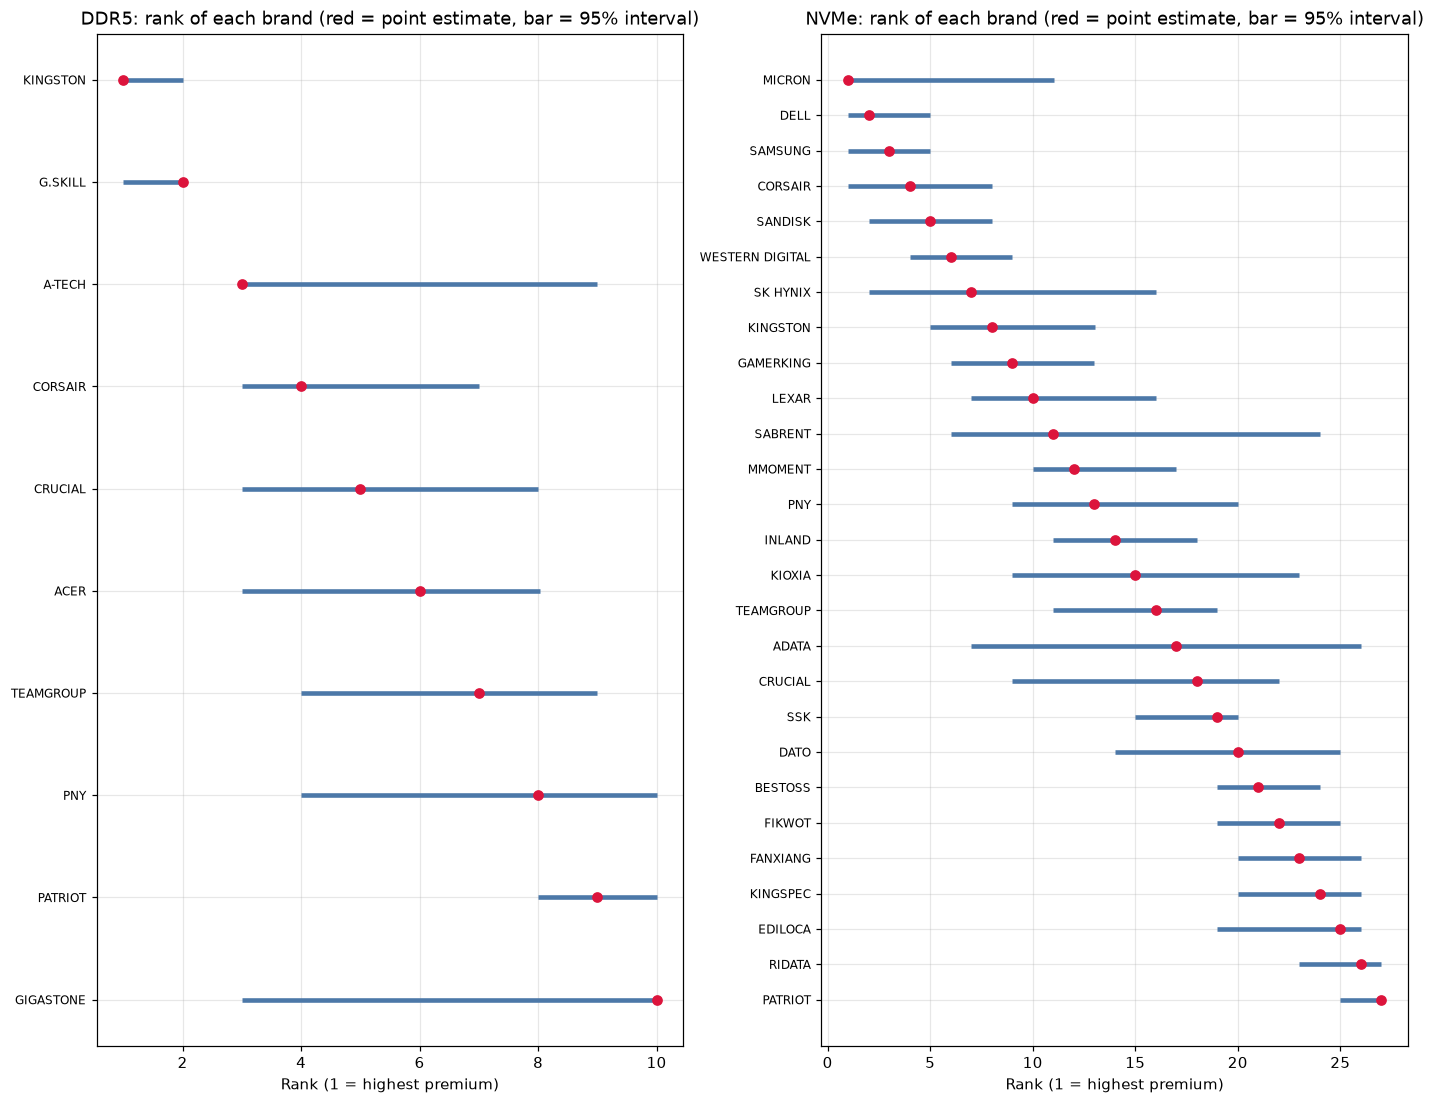

In [10]:
def rank_summary(boots, o):
    ranked = o["ranked"]
    rk = boots[ranked].rank(axis=1, ascending=False)
    k = max(1, min(3, len(ranked) // 2))
    point = fit(o).reindex(ranked)
    return pd.DataFrame({"prem_adj_%": point * 100, "rank_point": point.rank(ascending=False),
                         "rank_median": rk.median(), "rank_lo": rk.quantile(.025), "rank_hi": rk.quantile(.975),
                         f"P(top{k})": (rk <= k).mean(), f"P(bottom{k})": (rk > len(ranked) - k).mean()
                         }).sort_values("rank_point")

RANKS = {c: rank_summary(BOOT[c], OBJ[c]) for c in CATS}
for c in CATS:
    print(f"=== 5.1 {c}: bootstrap rank intervals (1 = highest premium) ===")
    display(RANKS[c].round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, max(4.5, 0.32 * max(len(OBJ[c]["ranked"]) for c in CATS) + 1.5)))
for a, c in zip(ax, CATS):
    r = RANKS[c].iloc[::-1]; y = np.arange(len(r))
    a.hlines(y, r["rank_lo"], r["rank_hi"], color="#4C78A8", lw=3)
    a.plot(r["rank_point"], y, "o", color="crimson")
    a.set_yticks(y); a.set_yticklabels(r.index, fontsize=8)
    a.set(title=f"{c}: rank of each brand (red = point estimate, bar = 95% interval)", xlabel="Rank (1 = highest premium)")
plt.tight_layout(); plt.show()

In [11]:
def split_half(o, n_rep=500, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(o["y"]); ir = [o["brands"].index(b) for b in o["ranked"]]
    rhos = []
    for _ in range(n_rep):
        perm = rng.permutation(n); a, b = perm[: n // 2], perm[n // 2:]
        pa = premium(o["y"][a], o["B"][a], o["C"][a], o["w"][a])[ir]
        pb = premium(o["y"][b], o["B"][b], o["C"][b], o["w"][b])[ir]
        ok = ~np.isnan(pa) & ~np.isnan(pb)
        if ok.sum() >= 4:
            rhos.append(stats.spearmanr(pa[ok], pb[ok])[0])
    return np.array(rhos)

SH = {}
rows = []
for c in CATS:
    r = split_half(OBJ[c]); SH[c] = r
    mean = np.nanmean(r)
    rows.append({"category": c, "n_ranked_brands": len(OBJ[c]["ranked"]), "valid_splits": len(r),
                 "mean_rho": mean, "rho_2.5%": np.nanpercentile(r, 2.5), "rho_97.5%": np.nanpercentile(r, 97.5),
                 "spearman_brown_full_sample": 2 * mean / (1 + mean)})
print("5.2 split-half reliability of the brand ranking (random halves of PRODUCTS)")
pd.DataFrame(rows).round(3)

5.2 split-half reliability of the brand ranking (random halves of PRODUCTS)


,category,n_ranked_brands,valid_splits,mean_rho,rho_2.5%,rho_97.5%,spearman_brown_full_sample
0,DDR5,10,500,0.629,0.249,0.903,0.772
1,NVMe,27,500,0.802,0.661,0.911,0.890


**Reading 5.1 / 5.2.**
- **Split-half reliability.** DDR5 ρ = **0.63** (95 % of random splits between 0.25 and 0.90; Spearman–Brown-corrected 0.77); NVMe ρ = **0.80** (0.66–0.91; corrected 0.89). By the rule of thumb the NVMe ranking is reliable at the coarse level, the DDR5 ranking only in its broad structure (10 brands and 221 products are few).
- **DDR5: only the ends are stable.** Kingston and G.SKILL occupy ranks 1–2 in 95 % of resamples (interval [1, 2], P(top-3) = 1.00), but their order is not decided (+13.7 % vs +13.1 %). Patriot is at the bottom (interval [8, 10], P(bottom-3) = 1.00). Ranks 3–7 (A-Tech, Corsair, Crucial, Acer, TeamGroup) have premiums within about 6 percentage points of each other (−2.2 % to −8.4 %) and rank intervals 5–7 places wide: **these five are statistically interchangeable**.
- **NVMe: coarse tiers are stable, neighbours are not.** Dell [1, 5] and Samsung [1, 5] are in the top 3 with probability 0.77 and 0.66; Corsair [1, 8]; Micron has the highest point estimate but a rank interval of [1, 11] because it has only 11 products. At the bottom Patriot [25, 27] (P(bottom-3) = 0.98) and Ridata [23, 27] (0.92) are consistent; Kingspec, Ediloca and Fanxiang have a 20–40 % chance of being in the bottom 3. Brands in the middle (ranks 9–20) have intervals 10–20 places wide (e.g. Sabrent [6, 24], ADATA [7, 26]).

In [12]:
dates = np.sort(df["observed_date"].unique())
FIRST, LAST = dates[:7], dates[-7:]
FOUR = np.array_split(dates, 4)
ATTR_COLS = PKEY + ["brand"] + sorted({c for v in CONTROLS.values() for c in v}) + ["n_rows"]

def window_ppu(d, dts, min_days=3):
    w = d[d["observed_date"].isin(dts)]
    g = w.groupby(PKEY, observed=True).agg(ppu=("price_per_unit_recomputed", "median"),
                                           n_days=("observed_date", "nunique"))
    g = g[g["n_days"] >= min_days]
    g.index = g.index.set_levels(g.index.levels[0].astype(str), level=0)
    return g

def time_premiums(cat, windows, names, min_products=3, fixed=True):
    attrs = prod_en.loc[prod_en["category"] == cat, ATTR_COLS].set_index(PKEY)
    per = [window_ppu(df[df["category"] == cat], w)[["ppu"]] for w in windows]
    if fixed:
        common = per[0].index
        for x in per[1:]:
            common = common.intersection(x.index)
        per = [x.loc[common] for x in per]
    frames = [attrs.join(x, how="inner").reset_index() for x in per]
    counts = [f["brand"].value_counts() for f in frames]
    ref = counts[0] if fixed else None
    if fixed:
        ranked = [b for b, n in ref.items() if n >= min_products and b not in NON_BRANDS]
    else:
        ranked = [b for b in counts[0].index if b not in NON_BRANDS and all(cn.get(b, 0) >= min_products for cn in counts)]
    prem = pd.DataFrame({nm: fit(prep(f, cat, ranked=ranked)).reindex(ranked) * 100 for nm, f in zip(names, frames)})
    return prem, [len(f) for f in frames]

def agreement(prem):
    rows = []
    for a, b in itertools.combinations(prem.columns, 2):
        ok = prem[[a, b]].dropna()
        if len(ok) >= 4:
            rows.append({"pair": f"{a} vs {b}", "n_brands": len(ok),
                         "spearman": stats.spearmanr(ok[a], ok[b])[0], "kendall": stats.kendalltau(ok[a], ok[b])[0]})
        else:
            rows.append({"pair": f"{a} vs {b}", "n_brands": len(ok), "spearman": np.nan, "kendall": np.nan})
    return pd.DataFrame(rows)

TIME = {}
for c in CATS:
    for tag, fixed in [("fixed catalog", True), ("any product", False)]:
        prem, n = time_premiums(c, [FIRST, LAST], ["first 7d", "last 7d"], fixed=fixed)
        TIME[(c, tag)] = prem
        print(f"=== 5.3 {c} - {tag}: products per window {n}, ranked brands {len(prem)} ===")
        display(agreement(prem).round(3))

=== 5.3 DDR5 - fixed catalog: products per window [55, 55], ranked brands 7 ===


,pair,n_brands,spearman,kendall
0,first 7d vs last 7d,7,0.929,0.81


=== 5.3 DDR5 - any product: products per window [99, 93], ranked brands 8 ===


,pair,n_brands,spearman,kendall
0,first 7d vs last 7d,8,0.881,0.714


=== 5.3 NVMe - fixed catalog: products per window [305, 305], ranked brands 27 ===


,pair,n_brands,spearman,kendall
0,first 7d vs last 7d,27,0.976,0.897


=== 5.3 NVMe - any product: products per window [507, 492], ranked brands 37 ===


,pair,n_brands,spearman,kendall
0,first 7d vs last 7d,37,0.933,0.796


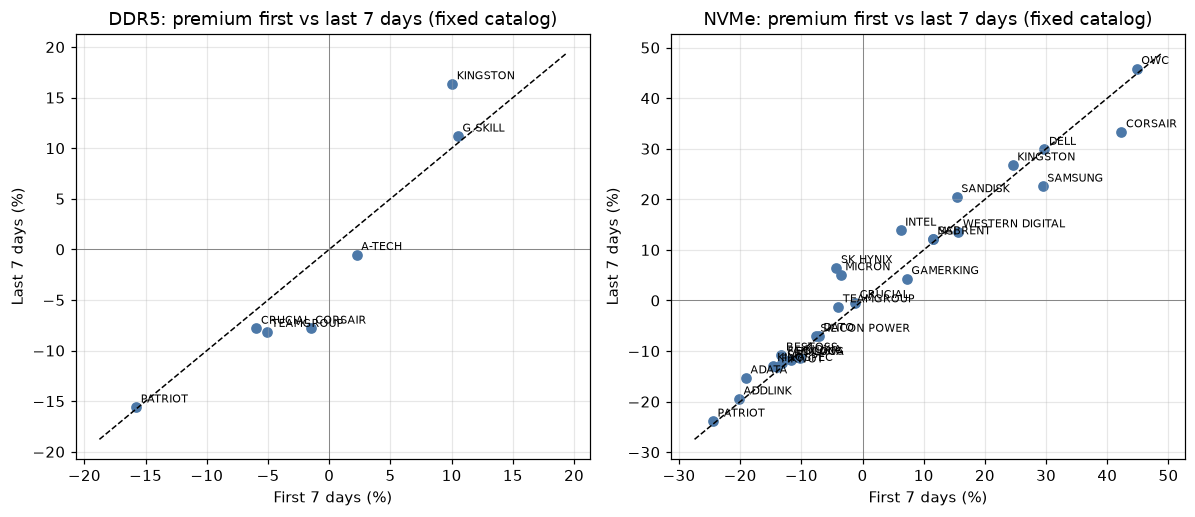

=== DDR5: 4 windows, fixed catalog: 50 products, 6 ranked brands ===


,W1,W2,W3,W4
G.SKILL,10.4,11.6,10.6,11.0
TEAMGROUP,-4.9,-8.2,-8.7,-8.2
CRUCIAL,-7.6,-6.7,-6.3,-9.3
CORSAIR,-4.6,-7.5,-9.7,-10.6
KINGSTON,10.3,17.6,17.4,16.6
PATRIOT,-15.1,-18.0,-17.3,-16.6


,W1,W2,W3,W4
W1,1.00,0.77,0.71,0.77
W2,0.77,1.00,0.94,0.83
W3,0.71,0.94,1.00,0.94
W4,0.77,0.83,0.94,1.00


=== NVMe: 4 windows, fixed catalog: 279 products, 26 ranked brands ===


,W1,W2,W3,W4
WESTERN DIGITAL,18.0,16.3,14.4,16.6
SAMSUNG,28.5,23.7,20.9,21.1
KINGSPEC,-13.8,-12.0,-11.6,-12.0
FIKWOT,-13.7,-12.6,-12.4,-12.8
FANXIANG,-13.0,-10.7,-11.2,-11.6
CRUCIAL,-1.2,-0.4,-1.0,-0.9
EDILOCA,-10.6,-11.0,-10.7,-10.6
BESTOSS,-11.6,-12.8,-9.1,-8.6
KIOXIA,-6.6,-8.5,-7.6,-7.4
DELL,26.6,28.8,29.0,25.4


,W1,W2,W3,W4
W1,1.00,0.98,0.98,0.99
W2,0.98,1.00,0.98,0.98
W3,0.98,0.98,1.00,1.00
W4,0.99,0.98,1.00,1.00


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a, c in zip(ax, CATS):
    t = TIME[(c, "fixed catalog")].dropna()
    a.scatter(t["first 7d"], t["last 7d"], color="#4C78A8")
    for b, r in t.iterrows():
        a.annotate(b, (r["first 7d"], r["last 7d"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    lim = [min(t.min().min(), 0) - 3, t.max().max() + 3] if len(t) else [-10, 10]
    a.plot(lim, lim, "k--", lw=1); a.axhline(0, color="grey", lw=.6); a.axvline(0, color="grey", lw=.6)
    a.set(title=f"{c}: premium first vs last 7 days (fixed catalog)", xlabel="First 7 days (%)", ylabel="Last 7 days (%)")
plt.tight_layout(); plt.show()

# 4 consecutive windows, fixed catalog (products with >= 3 days in every window)
for c in CATS:
    prem4, n4 = time_premiums(c, FOUR, [f"W{i+1}" for i in range(4)], fixed=True)
    print(f"=== {c}: 4 windows, fixed catalog: {n4[0]} products, {len(prem4)} ranked brands ===")
    display(prem4.round(1)); display(prem4.corr(method="spearman", min_periods=4).round(2))

**Reading 5.3 (time stability).**
- **First 7 vs last 7 days, same products (fixed catalog):** Spearman ρ = **0.93** for DDR5 (7 brands, 55 products per window) and **0.98** for NVMe (27 brands, 305 products); Kendall τ 0.81 and 0.90. When the product list may differ ("any product") ρ falls to 0.88 (DDR5) and 0.93 (NVMe): about 0.05 of the instability is a **changing catalogue**, the rest is real re-pricing or sampling.
- **Four consecutive windows.** NVMe: ρ between 0.98 and 1.00 for every pair of windows (26 brands, 279 products). DDR5: 0.71–0.94 (only 6 brands and 50 products; W1 is the least similar to the others), so treat it as indicative.
- **Brand-specific moves inside the same products** (premium is relative to the market average, so a move means the brand re-priced differently from the rest): DDR5 Kingston +10.3 % → +16.6 % and Corsair −4.6 % → −10.6 % (W1 → W4); NVMe SK hynix −0.9 % → +12.0 %, Intel +7.5 % → +15.4 %, Micron −2.7 % → +5.8 %, Samsung +28.5 % → +21.1 %, Corsair +46.7 % → +37.5 %. Most brands move by less than 3 points. The moves are too small to re-order the ranking, apart from the neighbours in the middle.
- A uniform price rise across all brands would leave ranks unchanged; only brand-specific moves like the ones above change premiums.

In [14]:
# 5.4 across ZIP markets (same ranked brands as the pooled analysis)
zip_ppu = (df.groupby(PKEY + ["geography_id"], observed=True)["price_per_unit_recomputed"].median().rename("ppu").reset_index())
zip_ppu["category"] = zip_ppu["category"].astype(str)
attrs_all = prod_en[ATTR_COLS]
ZIPR = {}
for c in CATS:
    ranked = OBJ[c]["ranked"]
    cols = {}
    for z, g in zip_ppu[zip_ppu["category"] == c].groupby("geography_id"):
        f = g.drop(columns="geography_id").merge(attrs_all, on=PKEY, how="left")
        cols[z] = fit(prep(f, c, ranked=ranked)).reindex(ranked) * 100
    pz = pd.DataFrame(cols); pz.insert(0, "pooled", fit(OBJ[c]).reindex(ranked) * 100)
    ZIPR[c] = pz
    rho = pz.drop(columns="pooled").apply(lambda s: stats.spearmanr(s, pz["pooled"], nan_policy="omit")[0])
    print(f"=== 5.4 {c}: Spearman of each ZIP's brand ranking vs the pooled ranking ({pz.drop(columns='pooled').shape[1]} ZIPs) ===")
    print(rho.round(3).describe()[["min", "50%", "max"]].to_string())

# 5.5 across capacity tiers (cap_tier control removed, brands need >= 3 products inside the tier)
TIER = {}
for c in CATS:
    cols = {}
    for tier, g in prod_en[prod_en["category"] == c].groupby("cap_tier"):
        if len(g) < 12:
            continue
        o = prep(g, c, min_products=3, ctrl_cols=[k for k in CONTROLS[c] if k != "cap_tier"])
        cols[f"{tier} (n={len(g)})"] = fit(o).reindex(o["ranked"]) * 100
    TIER[c] = pd.DataFrame(cols)
    print(f"=== 5.5 {c}: adjusted premium (%) inside each capacity tier; NaN = brand has < 3 products there ===")
    display(TIER[c].round(1))
    print("Spearman between tiers (pairwise, >= 4 common brands):")
    display(TIER[c].corr(method="spearman", min_periods=4).round(2))

=== 5.4 DDR5: Spearman of each ZIP's brand ranking vs the pooled ranking (12 ZIPs) ===
min    0.636
50%    0.897
max    0.952
=== 5.4 NVMe: Spearman of each ZIP's brand ranking vs the pooled ranking (12 ZIPs) ===
min    0.9580
50%    0.9685
max    0.9880
=== 5.5 DDR5: adjusted premium (%) inside each capacity tier; NaN = brand has < 3 products there ===


,16GB (n=42),24-32GB (n=91),48-64GB (n=47),>=96GB (n=32)
A-TECH,1.6,NaN,NaN,NaN
ACCLAMATOR,NaN,-20.9,NaN,NaN
ACER,NaN,-4.3,NaN,NaN
CORSAIR,-1.2,-2.2,-13.6,NaN
CRUCIAL,3.6,-1.0,-8.9,-32.7
G.SKILL,0.9,14.3,8.2,17.2
KINGSTON,23.0,11.9,7.8,NaN
LEXAR,NaN,-14.4,NaN,NaN
PATRIOT,-8.4,-15.2,NaN,NaN
TEAMGROUP,NaN,-7.0,NaN,NaN


Spearman between tiers (pairwise, >= 4 common brands):


,16GB (n=42),24-32GB (n=91),48-64GB (n=47),>=96GB (n=32)
16GB (n=42),1.0,0.7,0.4,NaN
24-32GB (n=91),0.7,1.0,1.0,NaN
48-64GB (n=47),0.4,1.0,1.0,NaN
>=96GB (n=32),NaN,NaN,NaN,NaN


=== 5.5 NVMe: adjusted premium (%) inside each capacity tier; NaN = brand has < 3 products there ===


,1TB (n=267),2TB (n=196),512GB (n=200),<=256GB (n=167),>=4TB (n=77)
ADATA,0.8,2.6,NaN,NaN,NaN
ADDLINK,-16.0,NaN,NaN,NaN,NaN
BESTOSS,-11.9,-10.0,-14.5,NaN,-13.0
BIWIN,-8.1,NaN,NaN,NaN,NaN
COLORFUL,NaN,NaN,-30.3,-36.9,NaN
CORSAIR,48.4,20.3,NaN,NaN,NaN
CRUCIAL,10.8,-9.0,NaN,NaN,-5.1
DATO,-11.2,NaN,9.1,NaN,NaN
DELL,51.7,NaN,19.7,39.3,NaN
DOGFISH,NaN,NaN,NaN,21.8,NaN


Spearman between tiers (pairwise, >= 4 common brands):


,1TB (n=267),2TB (n=196),512GB (n=200),<=256GB (n=167),>=4TB (n=77)
1TB (n=267),1.00,0.91,0.84,0.81,0.80
2TB (n=196),0.91,1.00,0.90,0.88,0.58
512GB (n=200),0.84,0.90,1.00,0.82,0.77
<=256GB (n=167),0.81,0.88,0.82,1.00,1.00
>=4TB (n=77),0.80,0.58,0.77,1.00,1.00


**Reading 5.4 / 5.5.**
- **ZIP markets.** NVMe: each ZIP's ranking has ρ = 0.96–0.99 (median 0.97) with the pooled ranking. DDR5: min 0.64, median 0.90, max 0.95. The ZIP price gaps behind this are small (median 1.9 %, 99 % ≤ 16 % on the 8 % of product-days that differ), so the lower DDR5 values mainly reflect that a single ZIP holds only a few products per brand (some brands are missing there), not regional pricing. **No evidence that the ranking depends on the ZIP market.**
- **Capacity tiers, DDR5.** Too few brands per tier for a meaningful ρ (4 ranked brands or fewer in most tiers). Descriptively: G.SKILL is positive in all four tiers (+0.9 % to +17.2 %); Kingston's premium shrinks with capacity (+23.0 % at 16 GB, +11.9 % at 24–32 GB, +7.8 % at 48–64 GB); Crucial goes from +3.6 % to −32.7 % (≥ 96 GB); Patriot is negative in both tiers where it is observed.
- **Capacity tiers, NVMe.** Spearman between tiers 0.77–0.91 for most pairs, lowest 0.58 (2 TB vs ≥ 4 TB, where few brands qualify). **Samsung is +20 % to +45 % in all five tiers; Patriot, Bestoss, Fikwot and Fanxiang are negative in every tier where they are observed.** Brands with few products per tier are not stable (Crucial +10.8 % at 1 TB, −9.0 % at 2 TB; Sabrent −11.9 % at 2 TB, +61.2 % at ≥ 4 TB on 3 products), so a brand with a single large premium in one tier should not be generalised.

## 6. Robustness (D6): does the conclusion survive other reasonable choices?

Nine configurations. For each, premiums are re-estimated and compared with the main result on the brands they share: Spearman ρ of the ranking, share of brands whose **sign** (premium vs discount) is unchanged, and the largest absolute change in premium (percentage points). `no controls` is *expected* to differ — it shows what the controls do.

In [15]:
prod_noise = enrich(build_products(df_noise))
o1_5 = flag_outliers_iqr(prod_en, "ppu", by="category", k=1.5)
o3 = flag_outliers_iqr(prod_en, "ppu", by="category", k=3)
CONFIGS = [
    ("main", prod_en, {}),
    ("min_products lower (DDR5 3 / NVMe 5)", prod_en, dict(min_products="lo")),
    ("min_products higher (DDR5 10 / NVMe 15)", prod_en, dict(min_products="hi")),
    ("weight = listing rows", prod_en, dict(weight_col="n_rows")),
    ("no controls (raw)", prod_en, dict(ctrl_cols=[])),
    ("products seen >= 3 days", prod_en[prod_en["n_days"] >= 3], {}),
    ("drop IQR outliers k=1.5", prod_en[~o1_5], {}),
    ("drop IQR outliers k=3", prod_en[~o3], {}),
    ("keep noise rows (NAS)", prod_noise, {}),
]
def resolve(kw, c):
    kw = dict(kw)
    if kw.get("min_products") in ("lo", "hi"):
        kw["min_products"] = MIN_ALT[c][0 if kw["min_products"] == "lo" else 1]
    return kw

ROB = {}
for name, p_all, kw in CONFIGS:
    for c in CATS:
        o = prep(p_all, c, **resolve(kw, c))
        ROB[(name, c)] = (fit(o).reindex(o["ranked"]) * 100, len(o["p"]))

rows = []
for c in CATS:
    main = ROB[("main", c)][0]
    for name, _, _ in CONFIGS:
        s, n = ROB[(name, c)]
        j = pd.concat([main, s], axis=1, keys=["m", "s"]).dropna()
        rows.append({"category": c, "config": name, "n_products": n, "n_brands": len(s), "common_brands": len(j),
                     "spearman_vs_main": stats.spearmanr(j["m"], j["s"])[0] if len(j) >= 4 else np.nan,
                     "sign_agree": (np.sign(j["m"]) == np.sign(j["s"])).mean() if len(j) else np.nan,
                     "max_abs_diff_pp": (j["m"] - j["s"]).abs().max() if len(j) else np.nan})
ROBT = pd.DataFrame(rows)
ROBT.round(3)

,category,config,n_products,n_brands,common_brands,spearman_vs_main,sign_agree,max_abs_diff_pp
0,DDR5,main,221,10,10,1.000,1.000,0.000
1,DDR5,min_products lower (DDR5 3 / NVMe 5),221,12,10,1.000,1.000,1.449
2,DDR5,min_products higher (DDR5 10 / NVMe 15),221,7,7,1.000,1.000,0.174
3,DDR5,weight = listing rows,221,10,10,0.976,0.900,6.300
4,DDR5,no controls (raw),221,10,10,0.830,1.000,6.324
5,DDR5,products seen >= 3 days,166,9,9,0.967,1.000,2.340
6,DDR5,drop IQR outliers k=1.5,213,10,10,0.903,1.000,4.594
7,DDR5,drop IQR outliers k=3,221,10,10,1.000,1.000,0.000
8,DDR5,keep noise rows (NAS),223,10,10,1.000,1.000,0.071
9,NVMe,main,907,27,27,1.000,1.000,0.000


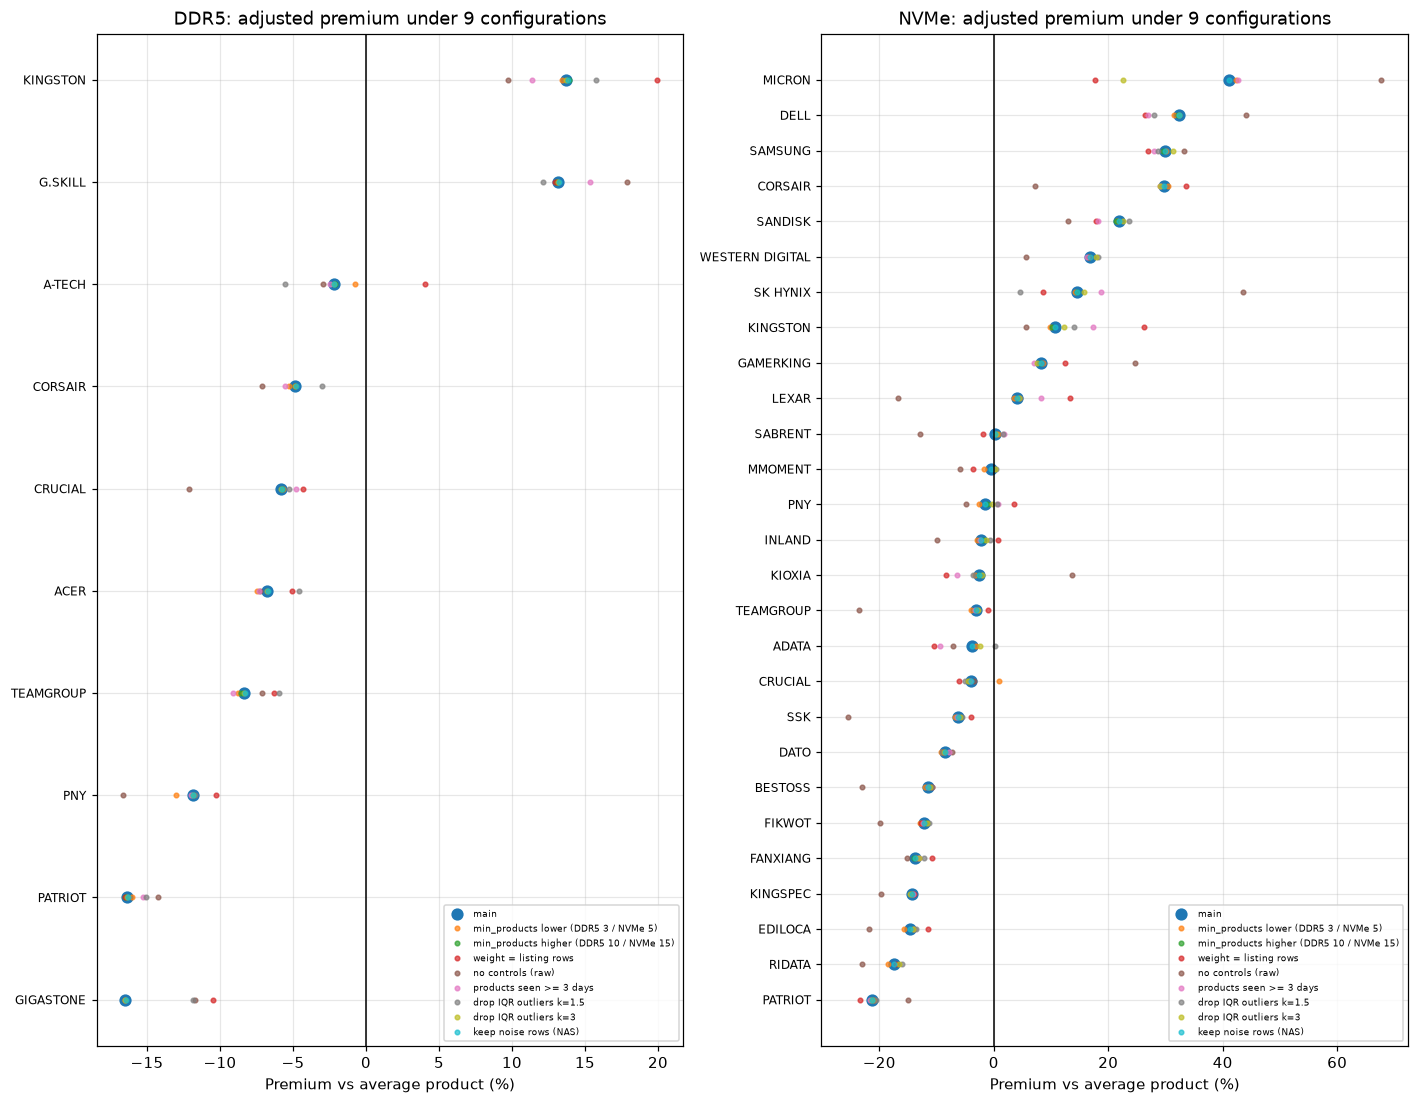

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, max(4.5, 0.32 * max(len(OBJ[c]["ranked"]) for c in CATS) + 1.5)))
colors = plt.cm.tab10(np.linspace(0, 1, len(CONFIGS)))
for a, c in zip(ax, CATS):
    order = ROB[("main", c)][0].sort_values().index
    y = np.arange(len(order))
    for (name, _, _), col in zip(CONFIGS, colors):
        s = ROB[(name, c)][0].reindex(order)
        a.plot(s.values, y, "o" if name == "main" else ".", ms=7 if name == "main" else 6, color=col, label=name,
               alpha=1 if name == "main" else .7)
    a.axvline(0, color="k", lw=1)
    a.set_yticks(y); a.set_yticklabels(order, fontsize=8)
    a.set(title=f"{c}: adjusted premium under 9 configurations", xlabel="Premium vs average product (%)")
    a.legend(fontsize=6, loc="lower right")
plt.tight_layout(); plt.show()

**Reading the robustness table / plot (D6).**
- **Ranking.** Leaving out `no controls`, the lowest Spearman ρ against the main result is **0.90** (DDR5, outliers k = 1.5) and **0.96** (NVMe, listing-row weights). Changing the brand threshold (DDR5 3 / 10, NVMe 5 / 15) gives ρ ≥ 0.98; adding the NAS rows or dropping the k = 3 outliers changes almost nothing.
- **Sign.** 90–100 % of DDR5 brands and 88–100 % of NVMe brands keep their sign in every configuration. The brands that flip are most likely those whose premium is already close to 0, which would be consistent with their CIs containing 0 (the table does not say which brands flip).
- **Size.** Weighting products by listing rows moves one brand by up to 6.3 points (DDR5) and 23.5 points (NVMe): the premium of a brand with few listing rows depends on how products are weighted. The large premiums and discounts (Samsung, Dell, Patriot, Fikwot…) are stable.
- **`no controls` is expected to differ**: ρ = 0.83 (DDR5) and 0.80 (NVMe); no DDR5 sign changes but 11 % of NVMe signs do, which confirms that a raw price-per-GB ranking is **not** a like-for-like ranking.

In [17]:
# Numbers for the written answer (copy into section 7)
for c in CATS:
    t = TAB[c].drop(index="OTHER", errors="ignore")
    print(f"##### {c} ({UNIT[c]}) #####")
    print("Highest premiums:"); print(t.head(3)[["n_products", "prem_raw_%", "prem_adj_%", "ci_low_%", "ci_high_%"]].round(1).to_string())
    print("Largest discounts:"); print(t.tail(3)[["n_products", "prem_raw_%", "prem_adj_%", "ci_low_%", "ci_high_%"]].round(1).to_string())
    print(f"brands with CI excluding 0: {int(t['ci_excludes_0'].sum())} of {len(t)}")
    print(f"R2 brand-only / controls-only / both: {r2_table(OBJ[c])['R2'].round(3).to_dict()}")
    print(f"split-half rho: mean {np.nanmean(SH[c]):.2f}, Spearman-Brown {2*np.nanmean(SH[c])/(1+np.nanmean(SH[c])):.2f}")
    r = ROBT[(ROBT['category'] == c) & ~ROBT['config'].isin(['main', 'no controls (raw)'])]
    print(f"robustness: min Spearman vs main {r['spearman_vs_main'].min():.2f}, min sign agreement {r['sign_agree'].min():.2f}")

##### DDR5 (USD per GB) #####
Highest premiums:
          n_products  prem_raw_%  prem_adj_%  ci_low_%  ci_high_%
grp                                                              
KINGSTON          15         9.7        13.7       6.2       21.7
G.SKILL           71        17.9        13.1       8.7       19.2
A-TECH            15        -2.9        -2.2     -13.5        8.3
Largest discounts:
           n_products  prem_raw_%  prem_adj_%  ci_low_%  ci_high_%
grp                                                               
PNY                 5       -16.6       -11.9     -18.3       -4.5
PATRIOT            15       -14.3       -16.4     -20.6      -12.0
GIGASTONE           5       -11.7       -16.5     -32.7       -1.4
brands with CI excluding 0: 8 of 10
R2 brand-only / controls-only / both: {'controls only': 0.376, 'brand only': 0.345, 'brand + controls': 0.559}
split-half rho: mean 0.63, Spearman-Brown 0.77
robustness: min Spearman vs main 0.90, min sign agreement 0.90
##### NVMe 

## 7. Answer, practical meaning, limitations

**Answer (with numbers).** Premium = % above (+) or below (−) the average product of the market, at the same capacity tier, form factor and speed (DDR5) or PCIe generation (NVMe). 95 % CI from a bootstrap over products.

- **DDR5 (USD per GB, 221 products, 10 ranked brands covering 90 % of products).**
  - Premium: **Kingston +13.7 %** [+6.2, +21.7] and **G.SKILL +13.1 %** [+8.7, +19.2].
  - Discount: **Patriot −16.4 %** [−20.6, −12.0], Gigastone −16.5 % [−32.7, −1.4], PNY −11.9 % [−18.3, −4.5], TeamGroup −8.4 %, Crucial −5.8 %, Corsair −4.9 % (CI barely excludes 0).
  - A-Tech and Acer cannot be told apart from the market.
- **NVMe (USD per TB, 907 products, 27 ranked brands covering 66 % of products).**
  - Premium: **Samsung +29.9 %** [+21.0, +39.9], Dell +32.4 %, Corsair +29.7 %, SanDisk +21.8 %, Western Digital +16.7 %, Micron +41.2 % (CI [+1.3, +105.6], 11 products).
  - Discount: **Patriot −21.4 %** [−26.4, −15.5], Ridata −17.5 %, Ediloca −14.6 %, Kingspec −14.2 %, Fanxiang −13.8 %, Fikwot −12.2 %, Bestoss −11.4 %.
  - 12 of 27 brands (including Crucial, Kingston, Lexar, Sabrent, PNY, Inland) are not distinguishable from the market average.
- **Raw vs adjusted.** Controls change many headline numbers (NVMe Corsair +7 % → +30 %; TeamGroup −24 % → −3 %; Lexar −17 % → +4 %; DDR5 Crucial −12 % → −6 %). Capacity, form factor and speed / PCIe explain more of the price per unit than brand does (R² 0.38 vs 0.35 in DDR5; 0.42 vs 0.20 in NVMe); brand adds about 0.12–0.18 R² on top.
- **Rank stability.** NVMe is reliable at the coarse level (split-half ρ 0.80; 0.98 first vs last week on the same products; 0.96–0.99 across ZIPs; ρ 0.77–0.91 across most capacity tiers). DDR5 is reliable only at the ends (ρ 0.63; Kingston and G.SKILL on top, Patriot at the bottom, ranks 3–7 interchangeable). Neighbouring ranks should not be read as an ordering in either category.
- **Robust?** Yes for the large effects: across nine configurations the sign is kept by 88–100 % of brands and ρ ≥ 0.90 against the main ranking (excluding the deliberate no-controls variant). Brands with premiums within about ±5 % are not robust, and the size of a small-volume brand's premium depends on the weighting.

**Practical meaning (illustrative).** The audit shows brand medians of about USD 14–18 per GB for DDR5: a 13 % premium is roughly USD 2/GB, i.e. about **USD 60 more for a 32 GB kit** than an equivalent product from an average brand, and Patriot would be about USD 2.5/GB (≈ USD 75 on 32 GB) cheaper. For NVMe, with medians around USD 200 per TB, Samsung's +30 % is about **USD 60 per TB (≈ USD 120 on a 2 TB drive)** compared with a like-for-like average drive. This is a statement about *what was listed during 21 Jul – 18 Aug 2026*, not a prediction, and it does not say the premium buys better quality.

**Surprises.**
1. Brand is not the main driver of price per unit: capacity, PCIe generation and speed explain as much or more.
2. Several apparent "cheap brands" (TeamGroup, Lexar, Sabrent) are cheap mostly because of what they sell; Corsair NVMe looks average in raw data but is about 30 % above the market like-for-like.
3. The ranking barely moves over 29 days even though 46 % of products changed price: prices move together.
4. The ZIP market does not change the ranking, as expected when most titles carry one price in every ZIP (the gap is a median 1.9 % on the product-days where it exists).

**Limitations (structural; keep unless the data show otherwise)**
- **Listed prices, 29 days, 12 ZIPs.** No transactions, no seasonality. Because a title is priced identically across ZIPs on about 92 % of product-days, the 12 ZIPs add little independent information about brands.
- **Title ≠ SKU** (data card). A product's median price can mix different items sold under one title.
- **Brand = first token of the title**, plus a hand-made fix list. Mis-parsed brands (e.g. resellers selling under another brand's name) blur the premiums. The audit in section 3 is the check.
- **Brand is confounded with product line.** Controls cover capacity, form factor, speed and PCIe generation, but *not* DRAM chip quality, heatsink, endurance (TBW), DRAM cache, warranty or retailer. An "adjusted premium" is therefore still not a pure brand effect, and it is **associational, not causal**.
- **Coverage of the NVMe ranking.** Ranked brands cover 66 % of NVMe products (118 are unbranded, about 190 are small brands); DDR5 coverage is 90 %. G.SKILL is 71 of 221 DDR5 products (many SKUs of a few lines), Samsung DDR5 has only 2 products and is not ranked.
- **Equal weight per product.** A brand with many cheap variants counts like a brand with one best-seller; the listing-row weighted version is in the robustness section. Products with several variants of one line are treated as independent in the bootstrap, so CIs are somewhat optimistic.
- **Reference = the average product of the market**, not the cheapest brand; premiums are relative and sum to roughly zero.
- **Brands with fewer than 5 (DDR5) / 10 (NVMe) products are not ranked** (pooled as `OTHER`); the ranking says nothing about small brands.
- **Unresolved capacity (4,357 rows)** and noise rows are excluded; products without a usable capacity cannot enter a per-GB / per-TB comparison.